In [120]:
import geopandas as gpd
import sys
import gzip, json
import numpy as np
import math
import torch
sys.path.insert(0, "../Raster2Seq")
sys.path.insert(0, "data/osm_carto_compare")

from render_carto import lonlat_to_px, pixel_window
from datasets.data_utils import sort_polygons, plot_polygons
from datasets.discrete_tokenizer import DiscreteTokenizer
from datasets.poly_data import ConvertToCocoDict
from util.plot_utils import plot_anno, plot_semantic_rich_floorplan_opencv

from matplotlib import pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
from PIL import Image
%matplotlib inline

In [121]:
with gzip.open("data/train10000/mapwarper_1000.geojson.gz", "rt") as fh:
    data = json.load(fh)

In [122]:
data["bbox"], data["metadata"];

In [123]:
# convert bounding box into pixels
zoom = data["metadata"]["source_zoom"]
pixel_window(data["bbox"], zoom)
x0, y0, x1, y1 = pixel_window(data["bbox"], zoom)
W, H = x1 - x0, y1 - y0

def to_px(lon, lat):
    px, py = lonlat_to_px(lon, lat, zoom)
    return (px - x0, py - y0)

In [124]:
polygons = []
for f in data["features"]:
    g = f["geometry"]
    if g["type"] == "Polygon":
        outer_rings = [g["coordinates"][0]]
    elif g["type"] == "MultiPolygon":
        outer_rings = [part[0] for part in g["coordinates"]]   # one outer ring per part
    else:
        continue

    for outer_ring in outer_rings:
        poly_px = []
        for lon, lat in outer_ring[:-1]:
            px, py = lonlat_to_px(lon, lat, zoom)
            poly_px.append((px - x0, py - y0))
        polygons.append((poly_px, f["properties"]["omt_layer"]))

In [125]:
from shapely.geometry import LineString, box
from shapely.ops import polygonize, unary_union

lines = []
for f in data["features"]:
    g = f["geometry"]
    if f["properties"]["omt_layer"] not in ("transportation", "waterway"):
        continue
    parts = [g["coordinates"]] if g["type"] == "LineString" else \
            g["coordinates"] if g["type"] == "MultiLineString" else []
    for line in parts:
        pts = [to_px(lon, lat) for lon, lat in line]
        if len(pts) >= 2:
            lines.append(LineString(pts))

lines.append(box(0, 0, W, H).exterior)          # map edge closes blocks at the border
blocks = [p for p in polygonize(unary_union(lines)) if p.area > 20]   # drop slivers

block_polygons = [(list(p.exterior.coords)[:-1], "block") for p in blocks]

In [126]:
points_only = [p for p, _ in polygons]
sorted_polys, order = sort_polygons(points_only, tolerance=20)
sorted_layers = [polygons[i][1] for i in order]
sorted_layers, sorted_polys;

In [127]:
layer_ids = {name: i for i, name in enumerate(sorted(set(sorted_layers)))}
labels = [layer_ids[l] for l in sorted_layers]

num_bins, seq_len = 64, 1024 # default values

size = max(W, H) - 1
norm_polys = [np.clip(np.array(p, dtype=np.float64) / size, 0, 1) for p in sorted_polys]

# 4. build a converter just for its sequence method
conv = ConvertToCocoDict(
    root="", augmentations=None, image_norm=False,
    poly2seq=True,
    semantic_classes=len(layer_ids) + 1,     # +1 for the "undefined" class used on separator tokens
    num_bins=64, seq_len=1024,               # passed through to DiscreteTokenizer
)
out = conv._get_bilinear_interpolation_coeffs(norm_polys, labels)

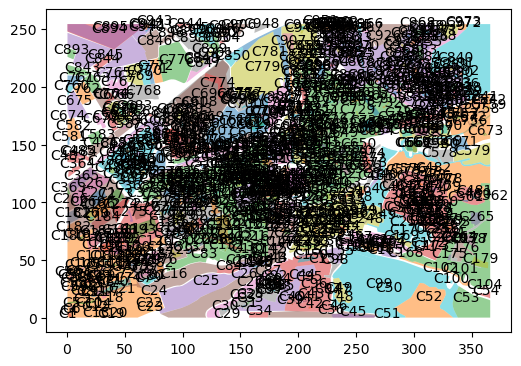

In [128]:
plot_polygons(sorted_polys, "polys.png")
# plt.close("all")

In [129]:
polygon_classes = set([c for _, c in polygons])
polygon_classes

# result from claude:
claude_polygons = [
  ([(0,55),(75,55),(140,75),(160,120),(145,165),(90,175),(20,165),(0,130),(0,55)],
   'park'),

  ([(0,320),(85,305),(145,315),(155,370),(110,415),(0,425),(0,320)],
   'park'),

  ([(275,445),(340,435),(405,445),(415,530),(270,530),(275,445)],
   'park'),

  ([(475,285),(530,280),(555,305),(540,335),(478,330),(475,285)],
   'park'),

  ([(0,175),(65,165),(125,175),(138,235),(95,255),(30,250),(0,240),(0,175)],
   'landuse'),

  ([(555,55),(680,55),(735,95),(735,270),(645,278),(568,238),(548,155),(555,55)],
   'landuse'),

  ([(535,345),(660,335),(735,355),(735,530),(515,530),(505,435),(520,380),(535,345)],
   'landuse'),

  ([(0,425),(185,415),(235,445),(225,530),(0,530),(0,425)],
   'landuse'),

  ([(220,155),(410,150),(445,195),(460,285),(390,315),(265,305),(205,262),(210,200),(220,155)],
   'landcover'),

  ([(145,55),(315,50),(325,135),(255,155),(155,145),(138,100),(145,55)],
   'landcover'),

  # Roads and rivers as thin polygons (buffered linestrings)
  ([(160,86),(430,83),(430,88),(160,91),(160,86)],
   'water'),

  ([(480,293),(735,313),(735,318),(480,298),(480,293)],
   'water'),

  ([(303,120),(307,120),(320,500),(316,500),(303,120)],
   'water'),

  ([(153,0),(167,0),(174,530),(160,530),(153,0)],
   'transportation'),

  ([(0,198),(735,190),(735,195),(0,203),(0,198)],
   'transportation'),

  ([(0,383),(355,351),(355,357),(0,389),(0,383)],
   'transportation'),

  ([(0,393),(355,361),(355,367),(0,399),(0,393)],
   'transportation'),

  ([(308,0),(318,0),(322,500),(312,500),(308,0)],
   'transportation'),

  ([(430,198),(735,353),(735,358),(430,203),(430,198)],
   'transportation'),

  ([(0,373),(340,346),(340,352),(0,379),(0,373)],
   'transportation'),
]

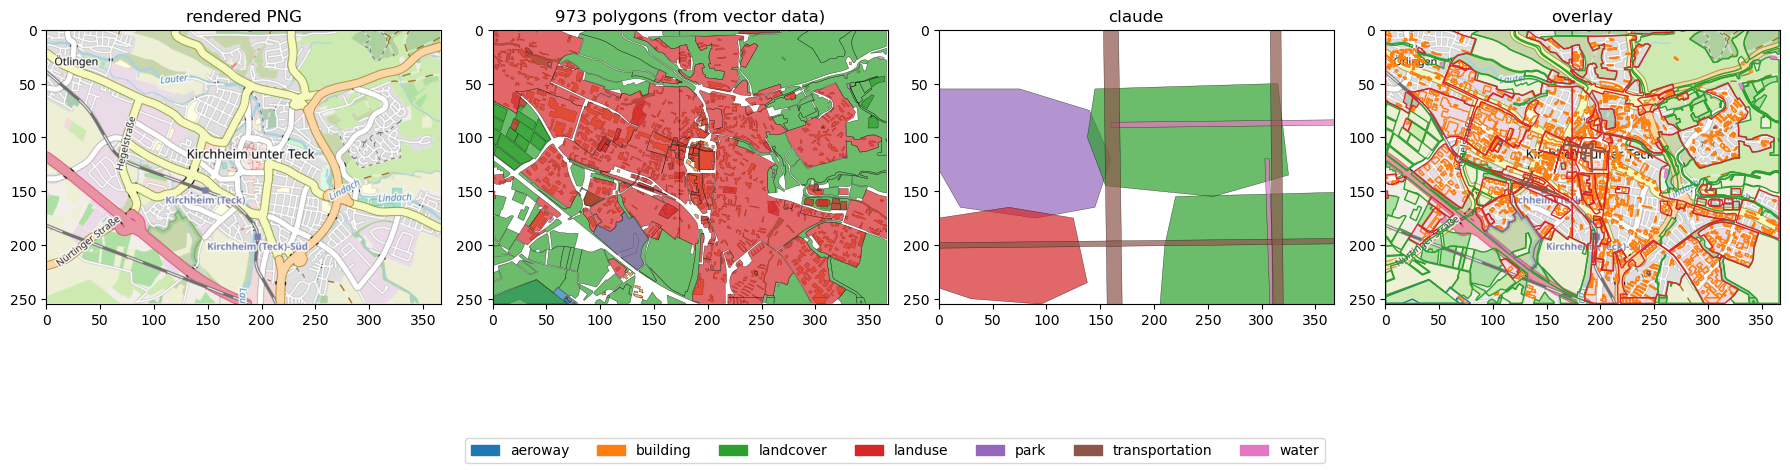

In [130]:
img = Image.open("data/train10000_png/mapwarper_1000.png")
#polygons = polygons + block_polygons
layers = sorted({layer for _, layer in polygons})
colors = dict(zip(layers, plt.cm.tab10.colors))

fig, axes = plt.subplots(1, 4, figsize=(18, 6))

axes[0].imshow(img, extent=(0, W, H, 0))
axes[0].set_title("rendered PNG")

for poly, layer in polygons:
    axes[1].add_patch(MplPolygon(poly, closed=True, facecolor=colors[layer],
                                 edgecolor="black", linewidth=0.3, alpha=0.7))
axes[1].set_title(f"{len(polygons)} polygons (from vector data)")


for poly, layer in claude_polygons:
    axes[2].add_patch(MplPolygon(poly, closed=True, facecolor=colors[layer],
                                 edgecolor="black", linewidth=0.3, alpha=0.7))
axes[2].set_title("claude")


axes[3].imshow(img, extent=(0, W, H, 0))
for poly, layer in polygons:
    axes[3].add_patch(MplPolygon(poly, closed=True, fill=False,
                                 edgecolor=colors[layer], linewidth=1))
axes[3].set_title("overlay")

for ax in axes:
    ax.set_xlim(0, W)
    ax.set_ylim(H, 0)                                # y increases downward, like the image
    ax.set_aspect("equal")

handles = [plt.Rectangle((0, 0), 1, 1, color=colors[l]) for l in layers]
fig.legend(handles, layers, loc="lower center", ncol=len(layers))
plt.tight_layout()
plt.show()